In [1]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import IsolationForest, RandomForestClassifier

df = pd.read_csv(r"C:\Users\Saurabh\OneDrive\Desktop\Youtube Channel\Python_Codes_YT\Churn_Dataset.csv")
print(f"Number of Records: {df.shape[0]} , Columns: {df.shape[1]}\n")
df.head()

Number of Records: 1000 , Columns: 11



,age,income_k,credit_score,tenure_years,num_products,monthly_usage,support_tickets,region,plan_type,auto_renew,churn_status
0,22,114.5,728,16.9,4,41.4,0,East,Premium,Yes,Retained
1,59,134.7,670,8.9,5,57.1,2,West,Basic,Yes,Retained
2,52,139.3,812,19.1,4,0.1,0,North,Basic,Yes,Churned
3,41,83.0,829,13.0,3,64.5,2,West,Standard,No,Retained
4,40,85.2,688,2.3,3,71.8,3,West,Premium,No,Retained


In [2]:
df.iloc[:, :-1].dtypes

age                  int64
income_k           float64
credit_score         int64
tenure_years       float64
num_products         int64
monthly_usage      float64
support_tickets      int64
region              object
plan_type           object
auto_renew          object
dtype: object

In [3]:
categorical_columns = ["region", "plan_type", "auto_renew"]

cat_df = df.loc[:, categorical_columns]
final_df = pd.concat([df.loc[:, [c for c in df.columns if ((c not in categorical_columns) & (c != 'churn_status'))]], pd.get_dummies(cat_df, dtype = int)], axis = 1)

print(f"{final_df.shape[0], final_df.shape[1]}")
print(f"Number of Records: {df.shape[0]} , Columns: {df.shape[1]}\n")
final_df.head()

(1000, 16)
Number of Records: 1000 , Columns: 11



,age,income_k,credit_score,tenure_years,num_products,monthly_usage,support_tickets,region_East,region_North,region_South,region_West,plan_type_Basic,plan_type_Premium,plan_type_Standard,auto_renew_No,auto_renew_Yes
0,22,114.5,728,16.9,4,41.4,0,1,0,0,0,0,1,0,0,1
1,59,134.7,670,8.9,5,57.1,2,0,0,0,1,1,0,0,0,1
2,52,139.3,812,19.1,4,0.1,0,0,1,0,0,1,0,0,0,1
3,41,83.0,829,13.0,3,64.5,2,0,0,0,1,0,0,1,1,0
4,40,85.2,688,2.3,3,71.8,3,0,0,0,1,0,1,0,1,0


In [4]:
le = LabelEncoder()

X = np.array(final_df)
Y = np.array(le.fit_transform(df.iloc[:, -1]))

idx = np.arange(len(X))
train_idx, test_idx = train_test_split(idx, test_size = 0.3, random_state = 0)

X_Train = X[train_idx, :]
X_Test = X[test_idx, :]
Y_Train = Y[train_idx]
Y_Test = Y[test_idx]

In [5]:
print(f"X Array:\n{X}\n")
print(f"Y Array (Encoded):\n{Y[0:10]}\n")
print(f"Y Array (Raw):\n{list(df.iloc[0:10, -1])}\n")

X Array:
[[ 22.  114.5 728.  ...   0.    0.    1. ]
 [ 59.  134.7 670.  ...   0.    0.    1. ]
 [ 52.  139.3 812.  ...   0.    0.    1. ]
 ...
 [ 37.  100.2 765.  ...   0.    1.    0. ]
 [ 68.   61.9 702.  ...   0.    1.    0. ]
 [ 45.  104.4 586.  ...   0.    1.    0. ]]

Y Array (Encoded):
[1 1 0 1 1 0 1 0 1 0]

Y Array (Raw):
['Retained', 'Retained', 'Churned', 'Retained', 'Retained', 'Churned', 'Retained', 'Churned', 'Retained', 'Churned']



In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_Std = scaler.fit_transform(X)

LR = LogisticRegression(random_state = 0)
LR.fit(X_Std[train_idx, :], Y_Train)
Y_Train_Main = LR.predict(X_Std[train_idx, :])
Y_Test_Main = LR.predict(X_Std[test_idx, :])

train_score_skl = np.round(f1_score(Y_Train, Y_Train_Main), 2)
test_score_skl = np.round(f1_score(Y_Test, Y_Test_Main), 2)

print(f"\nModel Performance, F1 - Train: {train_score_skl}, F1 - Test: {test_score_skl}\n")


Model Performance, F1 - Train: 0.77, F1 - Test: 0.77



In [7]:
print(LR.coef_)
print(LR.intercept_)

[[ 0.07964962  0.10763231  1.45015759  0.4152542   0.11958514  0.77319255
  -0.37751001 -0.07309322 -0.01383267  0.10764818 -0.02040439 -0.18616046
   0.03245823  0.16045047 -0.03654041  0.03654041]]
[-0.18599632]


In [8]:
np.random.seed(0)
beta = np.zeros(X_Train.shape[1])
inter = 0.0

def sigmoid(indep_vars, coeff, intercept):
    y = (-1) * (np.dot(indep_vars, coeff) + intercept)
    return (1 / ((1 + np.exp(y)) + 1e-06))

def gradient(dep_var, indep_vars, coeff, intercept):
    N = indep_vars.shape[0]
    y_pred = sigmoid(indep_vars, coeff, intercept)
    grad_coeff = (1 / N) * np.dot(indep_vars.T, (y_pred - dep_var))
    grad_intercept = np.mean(y_pred - dep_var)
    return np.append(grad_coeff, grad_intercept)

In [9]:
alpha = 0.01
params = beta.copy()
params = np.append(params, np.array(inter))

for i in range(1000):
    params = params - alpha * gradient(Y_Train, X_Std[train_idx, :], params[:-1], params[-1])
    
params

array([ 0.0557511 ,  0.08686098,  1.0501764 ,  0.27544288,  0.07854128,
        0.52474637, -0.26212927, -0.05392068, -0.01688461,  0.07387101,
       -0.00253819, -0.13171676,  0.00939852,  0.1259787 , -0.02584347,
        0.02584347, -0.1166059 ])

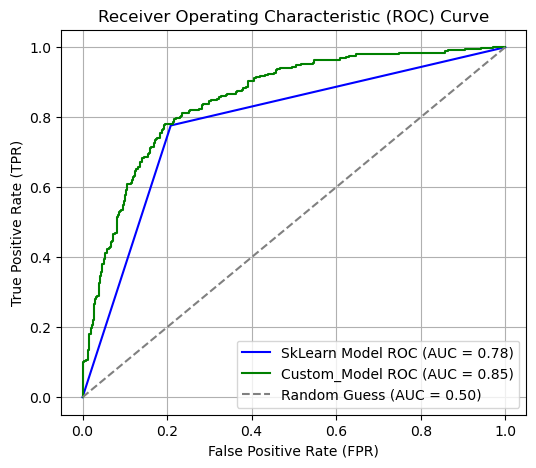

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

Y_Pred = sigmoid(X_Std[train_idx, :], params[:-1], params[-1])
fpr_lst, tpr_lst, thresholds_lst = roc_curve(Y_Train, Y_Pred)
fpr_skl_lst, tpr_skl_lst, thresholds_skl_lst = roc_curve(Y_Train, LR.predict(X_Std[train_idx, :]))
auc_score = roc_auc_score(Y_Train, Y_Pred)
auc_score_skl = roc_auc_score(Y_Train, LR.predict(X_Std[train_idx, :]))

dist = []
for i in range(len(fpr_lst)):
    dist.append(float(np.sqrt(((0 - fpr_lst[i]) ** 2) + ((1 - tpr_lst[i]) ** 2))))

final_thres = float(thresholds_lst[np.argmin(dist)])

plt.figure(figsize = (6, 5))
plt.plot(fpr_skl_lst, tpr_skl_lst, color = 'blue', label = f'SkLearn Model ROC (AUC = {auc_score_skl:.2f})')
plt.plot(fpr_lst, tpr_lst, color = 'green', label = f'Custom_Model ROC (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle='--', label='Random Guess (AUC = 0.50)')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc = 'lower right')
plt.grid(True)
plt.show()

In [11]:
final_thres

0.5075752020759218

In [12]:
Y_Train_Pred = np.where(sigmoid(X_Std[train_idx, :], params[:-1], params[-1]) > final_thres, 1, 0)
Y_Test_Pred = np.where(sigmoid(X_Std[test_idx, :], params[:-1], params[-1]) > final_thres, 1, 0)

train_score = np.round(f1_score(Y_Train, Y_Train_Pred), 2)
test_score = np.round(f1_score(Y_Test, Y_Test_Pred), 2)

print(f"\nModel (Self-Build) Performance, F1 - Train: {train_score}, F1 - Test: {test_score}\n")
print(f"Model (Sklearn) Performance, F1 - Train: {train_score_skl}, F1 - Test: {test_score_skl}\n")


Model (Self-Build) Performance, F1 - Train: 0.78, F1 - Test: 0.78

Model (Sklearn) Performance, F1 - Train: 0.77, F1 - Test: 0.77

